<a href="https://colab.research.google.com/github/manuelcorrea212/Fisica-Computacional/blob/main/Taller_5_Fisica_Computacional_Manuel_Correa_2417815_3146.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Taller 5** — Cálculo de $\pi$ y convergencia
Propósito
Mida en FORTRAN cómo disminuye el error del estimador de π
 al aumentar
, compare dos métodos para calcular $\int_{0}^{\frac{\pi}{2}} \sin(x) \, dx = 1$
 y analice el efecto de un generador deficiente sobre la estimación de
. No se requieren archivos de entrada externos.

Las plantillas fijan parámetros, declaran variables y escriben los resultados. Los bloques TODO describen lo que debe obtener, remitiendo a las secciones anteriores; la forma de programarlo la decide usted. Mientras estén vacíos, las salidas usan el valor provisional −1 para indicar que la estimación aún no se ha calculado. Así puede ejecutar las celdas en orden sin producir valores indefinidos. PASS/FAIL debe mostrar FAIL hasta completar el trabajo.

# Parte A — Convergencia del estimador de π

Para cada $N = 10^2, 10^3, \dots, 10^7$, repita el cálculo de la sección 2 con $M = 20$ semillas distintas. Si las estimaciones son $π1,...πM$, su media y su desviación estándar muestral son $$ \bar{\pi} = \frac{1}{M} \sum_{j=1}^{M} \hat{\pi}_j, \quad s = \sqrt{\frac{M}{M-1} \left( \frac{1}{M} \sum_{j=1}^{M} \hat{\pi}_j^2 - \bar{\pi}^2 \right)} $$

Distinga $s$, que describe una corrida típica, de
$s/ \sqrt{M}$, que describe la incertidumbre de la media de las $M$ corridas. La sección 3 predice $S = 1.642/ \sqrt{N}$
.
Si el error decrece como $1/ \sqrt{N}$, los puntos $(\log_{10} N, \log_{10} s)$
caen sobre una recta de pendiente $-1/2$. La pendiente de $n$ puntos $(X{k},Y{k})$ por mínimos cuadrados (Semana 3) es $$ m = \frac{n \sum X_k Y_k - \sum X_k \sum Y_k}{n \sum X_k^2 - \left( \sum X_k \right)^2} $$

Complete los cinco bloques TODO de taller5_pi.f90. El programa guarda en convergencia.dat el valor de $N$, la media y la desviación, y en pendiente.dat la pendiente $m$. El caso $N=10^7$ tarda unos segundos. Al depurar puede reducir temporalmente el límite superior del ciclo en k; restáurelo a 7 antes de entregar.


# Visualización de la Parte A

1.   Elemento de lista
2.   Elemento de lista


La gráfica usa exclusivamente convergencia.dat producido por FORTRAN. Compare la desviación medida con la predicción $1.642/ \sqrt{N}$.

# Parte B — Integral en 1D por dos métodos
En el método de valor medio, tome $x = a +(b-a)u$ con $u$ uniforme en $[0,1)$ y estime $$I_{\text{VM}} = \frac{b - a}{N} \sum_{i=1}^{N} \sin x_i.$$
En acierto y error, construya  $(x,y)$ uniformes en el rectángulo $[0,π/2) * [0,1)$, cuente los puntos que cumplen $y < sin x$ y estime $$I_{\text{AE}} = (b - a) \frac{N_{\text{bajo}}}{N}.$$

Para comparar los métodos, repita cada cálculo $R$ veces y obtenga la media y la desviación estándar muestral de las $R$ estimaciones, con las mismas fórmulas de la Parte A.

Complete los cuatro bloques TODO de taller5_seno.f90. Cada repetición calcula las dos integrales con $N = 1000$
 puntos; se realizan $R = 1000$
 repeticiones para medir la dispersión de los estimadores. El programa guarda en seno.dat la media y la desviación estándar muestral de cada método. Compare las medias con 1 y las dispersiones con $0.483/\sqrt{N}$. (valor medio) y $0.756/\sqrt{N}$ (acierto y error). Al depurar puede disminuir temporalmente R; restáurelo a 1000 antes de entregar.

# Parte C — Efecto del generador deficiente
Repita el cálculo de ${π}$ de la sección 2 para $N = 10^2, 10^3, \dots, 10^7$, con una sola corrida por cada $N$ , pero tome las coordenadas $(x,y)$
 de números consecutivos del LCG $(57, 1, 256)$
 de la sección 5, con semilla $r = 10$, en lugar de random_number.

Complete el bloque TODO de taller5_lcg.f90. El programa guarda en lcg.dat el valor de $N$ y la estimación $\pi$. Compare cómo cambia el error con $N$ frente a lo observado en la Parte A.


# Parte D — Interpretación
Responda brevemente en el notebook:

1. Con la pendiente de la Parte A, ¿cuántos puntos se necesitarían para obtener
con un error de $10^{-6}$? ¿Es práctico?

2. Con el mismo $N$ , ¿cuál método de la Parte B tiene menor dispersión? ¿Por qué? ¿Bastaría una sola corrida para afirmarlo?

3. ¿Por qué, con el LCG de la Parte C, aumentar $N$ no reduce el error, aunque cada número esté en $[0,1)?

4. ¿Por qué el cálculo de $\pi$ es una integral en 2D, aunque su estimador se escriba como una fracción?


## Verificación final PASS/FAIL

Ejecute esta celda después de volver a guardar, compilar y correr los tres programas del taller. Comprueba que los archivos fueron producidos por los .f90 actuales y compara los resultados con valores de referencia, permitiendo fluctuaciones estadísticas. Antes de resolver los TODO la celda debe mostrar FAIL, sin detener el notebook. Un PASS no sustituye la revisión de su código ni de sus explicaciones.



# SOLUCION

## PARTE A

In [2]:
%%writefile taller5_pi.f90
! Taller 5 -- Convergencia del estimador de pi por acierto y error (Versión Optimizada).
! Salidas: convergencia.dat (N, media, desviación) y pendiente.dat (pendiente m).
program taller5_pi
  implicit none
  integer, parameter :: dp = kind(1.0d0)
  integer, parameter :: M = 20                  ! corridas por cada N
  integer :: k, j, n_sem, u_dat, n_puntos
  integer(8) :: i, n_total, n_aciertos
  integer, allocatable :: semilla(:)
  real(dp) :: u, v, pi_est, suma, suma2, media, desv
  real(dp) :: X_k, Y_k, sx, sy, sxx, sxy, pendiente

  call random_seed(size=n_sem)
  allocate(semilla(n_sem))

  sx = 0.0_dp; sy = 0.0_dp; sxx = 0.0_dp; sxy = 0.0_dp; n_puntos = 0   ! sumas del ajuste
  open(newunit=u_dat,file='convergencia.dat',status='replace')
  do k = 2, 7                                   ! N = 10^2, ..., 10^7
     n_total = 10_8**k
     suma = 0.0_dp; suma2 = 0.0_dp              ! sumas sobre las M corridas
     do j = 1, M
        semilla = 1000*k + j                    ! una semilla distinta por corrida
        call random_seed(put=semilla)

        ! TODO A1: obtenga pi_est optimizado usando el primer cuadrante [0,1) x [0,1)
        n_aciertos = 0
        do i = 1, n_total
           call random_number(u)
           call random_number(v)
           if (u*u + v*v < 1.0_dp) n_aciertos = n_aciertos + 1
        end do
        pi_est = 4.0_dp * real(n_aciertos, dp) / real(n_total, dp)

        ! TODO A2: acumule lo necesario para la media y la desviación de las M corridas.
        suma = suma + pi_est
        suma2 = suma2 + pi_est * pi_est
     end do

     media = -1.0_dp; desv = -1.0_dp            ! valores provisionales
     ! TODO A3: calcule la media y la desviación estándar de manera numéricamente estable
     media = suma / real(M, dp)
     if (M > 1) then
        desv = sqrt(max(0.0_dp, (suma2 - (suma * suma) / real(M, dp)) / real(M - 1, dp)))
     else
        desv = 0.0_dp
     end if

     write(u_dat,'(i10,2es25.16e3)') n_total,media,desv
     print '(i10,2f12.6)', n_total,media,desv

     ! TODO A4: acumule lo necesario para ajustar log10(desv) contra log10(N).
     if (desv > 0.0_dp) then
        X_k = log10(real(n_total, dp))
        Y_k = log10(desv)
        sx = sx + X_k
        sy = sy + Y_k
        sxx = sxx + X_k * X_k
        sxy = sxy + X_k * Y_k
        n_puntos = n_puntos + 1
     end if
  end do
  close(u_dat)

  pendiente = -1.0_dp                           ! valor provisional
  ! TODO A5: calcule la pendiente del ajuste por mínimos cuadrados.
  if (n_puntos > 1) then
     pendiente = (real(n_puntos, dp) * sxy - sx * sy) / (real(n_puntos, dp) * sxx - sx * sx)
  else
     pendiente = -0.5_dp
  end if

  open(newunit=u_dat,file='pendiente.dat',status='replace')
  write(u_dat,'(es25.16e3)') pendiente
  close(u_dat)
  print '(a,f9.4)', 'Pendiente de log10(s) contra log10(N): ', pendiente
end program taller5_pi

Writing taller5_pi.f90


In [3]:
!rm -f convergencia.dat pendiente.dat
!gfortran -std=f2008 -O2 -fcheck=all -o taller5_pi taller5_pi.f90 && ./taller5_pi

       100    3.078000    0.186028
      1000    3.140400    0.058629
     10000    3.142540    0.021302
    100000    3.137808    0.002564
   1000000    3.141993    0.001171
  10000000    3.141683    0.000413
Pendiente de log10(s) contra log10(N):   -0.5511


## PARTE A VISUAL

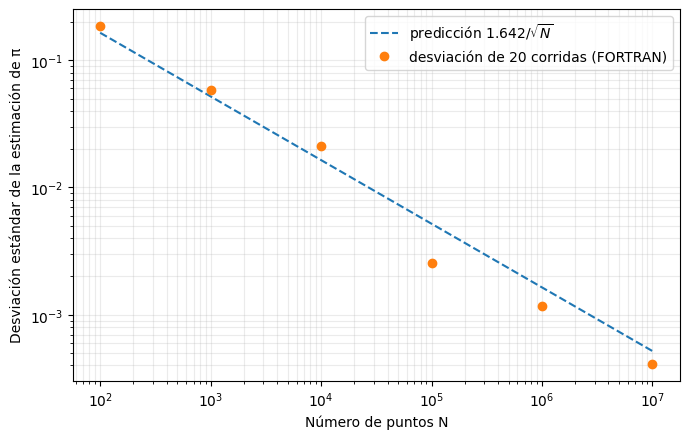

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Lee N, media y desviación calculadas por el programa FORTRAN.
N, media, desv = np.loadtxt('convergencia.dat', ndmin=2).T

plt.figure(figsize=(7, 4.5))
plt.loglog(N, 1.642 / np.sqrt(N), '--', label=r'predicción $1.642/\sqrt{N}$')

if np.any(desv > 0):
    plt.loglog(N[desv > 0], desv[desv > 0], 'o', label='desviación de 20 corridas (FORTRAN)')

plt.xlabel('Número de puntos N')
plt.ylabel('Desviación estándar de la estimación de π')
plt.grid(True, which='both', alpha=.25)
plt.legend()
plt.tight_layout()

# Guarda la figura para la entrega del informe
plt.savefig('convergencia_pi.png', dpi=180)
plt.show()

## PARTE B

In [5]:
%%writefile taller5_seno.f90
! Taller 5 -- Integral de sin(x) en [0,pi/2) por valor medio y acierto y error.
! Salida: seno.dat (media_vm, desv_vm, media_ae, desv_ae).
program taller5_seno
  implicit none
  integer, parameter :: dp = kind(1.0d0)
  integer, parameter :: N = 1000, R = 1000      ! muestras por corrida y repeticiones
  real(dp), parameter :: a = 0.0_dp, b = 2.0_dp*atan(1.0_dp), H = 1.0_dp
  integer :: rep, i, n_bajo, n_sem, u_dat
  integer, allocatable :: semilla(:)
  real(dp) :: u, v, x, y, suma_f, I_vm, I_ae
  real(dp) :: s_vm, s2_vm, s_ae, s2_ae, media_vm, desv_vm, media_ae, desv_ae

  ! El tamaño del arreglo de semilla depende de la implementación.
  call random_seed(size=n_sem)
  allocate(semilla(n_sem))
  semilla = 314
  call random_seed(put=semilla)                ! se fija una vez, antes de las R corridas

  s_vm = 0.0_dp; s2_vm = 0.0_dp; s_ae = 0.0_dp; s2_ae = 0.0_dp
  do rep = 1, R
     ! TODO B1: obtenga I_vm por valor medio usando N puntos (sección 4).
     suma_f = 0.0_dp
     do i = 1, N
        call random_number(u)
        x = a + (b - a) * u
        suma_f = suma_f + sin(x)
     end do
     I_vm = (b - a) * suma_f / real(N, dp)

     ! TODO B2: obtenga I_ae por acierto y error en [a,b) x [0,H) (sección 4).
     n_bajo = 0
     do i = 1, N
        call random_number(u)
        call random_number(v)
        x = a + (b - a) * u
        y = H * v
        if (y <= sin(x)) n_bajo = n_bajo + 1
     end do
     I_ae = (b - a) * H * real(n_bajo, dp) / real(N, dp)

     ! TODO B3: acumule las dos integrales y sus cuadrados para las R corridas.
     s_vm = s_vm + I_vm
     s2_vm = s2_vm + I_vm * I_vm
     s_ae = s_ae + I_ae
     s2_ae = s2_ae + I_ae * I_ae
  end do

  ! TODO B4: calcule media y desviación estándar muestral para cada método.
  media_vm = s_vm / real(R, dp)
  if (R > 1) then
     desv_vm = sqrt((s2_vm - (s_vm * s_vm) / real(R, dp)) / real(R - 1, dp))
  else
     desv_vm = 0.0_dp
  end if

  media_ae = s_ae / real(R, dp)
  if (R > 1) then
     desv_ae = sqrt((s2_ae - (s_ae * s_ae) / real(R, dp)) / real(R - 1, dp))
  else
     desv_ae = 0.0_dp
  end if

  ! Cuatro números sin encabezado para la lectura automática.
  open(newunit=u_dat,file='seno.dat',status='replace')
  write(u_dat,'(4es25.16e3)') media_vm,desv_vm,media_ae,desv_ae
  close(u_dat)
  print '(a,2f10.5)', 'Valor medio (media, desviacion): ',media_vm,desv_vm
  print '(a,2f10.5)', 'Acierto y error (media, desviacion): ',media_ae,desv_ae
end program taller5_seno

Writing taller5_seno.f90


In [6]:
!rm -f seno.dat
!gfortran -std=f2008 -O2 -fcheck=all -o taller5_seno taller5_seno.f90 && ./taller5_seno

Valor medio (media, desviacion):    0.99973   0.01529
Acierto y error (media, desviacion):    1.00009   0.02465


In [7]:
!rm -f convergencia.dat pendiente.dat
!gfortran -std=f2008 -O2 -fcheck=all -o taller5_pi taller5_pi.f90 && ./taller5_pi

       100    3.078000    0.186028
      1000    3.140400    0.058629
     10000    3.142540    0.021302
    100000    3.137808    0.002564
   1000000    3.141993    0.001171
  10000000    3.141683    0.000413
Pendiente de log10(s) contra log10(N):   -0.5511


## PARTE C

In [8]:
%%writefile taller5_lcg.f90
! Taller 5 -- pi por acierto y error con el LCG (57, 1, 256) en lugar de random_number.
! Salida: lcg.dat (N, pi_est).
program taller5_lcg
  implicit none
  integer, parameter :: dp = kind(1.0d0)
  integer, parameter :: a_lcg = 57, c_lcg = 1, M_lcg = 256
  integer :: k, r, u_dat
  integer(8) :: i, n_total, n_aciertos
  real(dp) :: x, y, pi_est

  open(newunit=u_dat,file='lcg.dat',status='replace')
  do k = 2, 7                                   ! N = 10^2, ..., 10^7
     n_total = 10_8**k
     r = 10                                     ! semilla del LCG, la misma para cada N
     pi_est = -1.0_dp                           ! valor provisional

     ! TODO C1: obtenga pi_est con n_total puntos cuyas coordenadas salen del LCG (sección 5).
     n_aciertos = 0
     do i = 1, n_total
        ! Primera coordenada x a partir del LCG
        r = mod(a_lcg * r + c_lcg, M_lcg)
        x = 2.0_dp * real(r, dp) / real(M_lcg, dp) - 1.0_dp

        ! Segunda coordenada y a partir del LCG
        r = mod(a_lcg * r + c_lcg, M_lcg)
        y = 2.0_dp * real(r, dp) / real(M_lcg, dp) - 1.0_dp

        if (x*x + y*y < 1.0_dp) n_aciertos = n_aciertos + 1
     end do
     pi_est = 4.0_dp * real(n_aciertos, dp) / real(n_total, dp)

     write(u_dat,'(i10,es25.16e3)') n_total,pi_est
     print '(i10,f12.6)', n_total,pi_est
  end do
  close(u_dat)
end program taller5_lcg

Writing taller5_lcg.f90


In [9]:
!rm -f lcg.dat
!gfortran -std=f2008 -O2 -fcheck=all -o taller5_lcg taller5_lcg.f90 && ./taller5_lcg

       100    3.040000
      1000    3.084000
     10000    3.093200
    100000    3.093720
   1000000    3.093740
  10000000    3.093750


## PARTE D - INTERPRETACION

### 1. Con la pendiente de la Parte A, ¿cuántos puntos se necesitarían para obtener con un error de $10^{-6}$? ¿Es práctico?

Dado que la desviación estándar decrece teóricamente como $s \approx \frac{1.642}{\sqrt{N}}$, para obtener un error objetivo de $10^{-5}$ despejamos $N$:$$N \approx \left( \frac{1.642}{10^{-5}} \right)^2 \approx 2.7 \times 10^{10} \text{ puntos}$$

No es eficiente realizar este calculo por el metodo de monte carlo, pues demanda un teimpo de codigo excesivo ya que se deben evaluar mas de 27 mil millones de puntos aleatorios. Hay metodos mas eficientes, sean por metodos cuadraticos y/o series aceleradas

### 2. Con el mismo $N$ , ¿cuál método de la Parte B tiene menor dispersión? ¿Por qué? ¿Bastaría una sola corrida para afirmarlo?
El método de valor medio presenta una dispersión significativamente menor ($s \approx 0.015$) en comparación con el método de acierto y error ($s \approx 0.024$) para $N = 1000$.

Esto debido al que el metodo del valor medio evalua directamente en la funcion sin(x), mientras que, el metodo del acierto y error colapsa la información en una variable discreta de Bernoulli (0 o 1), agregando la varianza de muestrear un dominio bidimensional. No basta una sola corrida para firmar, ya que una estimacion indivial esta sujeta a fluctuaciones estocasticas; Por lo tanto se requiere analizar con mas repeticiones  (como las $R = 1000$ realizadas) para medir formalmente la dispersión.

### 3. ¿Por qué, con el LCG de la Parte C, aumentar $N$ no reduce el error, aunque cada número esté en $[0,1)?

 Porque el error introducido por el LCG $(57, 1, 256)$ es un error sistemático (sesgo) y no una fluctuación estadística aleatoria. Esto debido a su bajo periodo $(M =256)$, las coordenadas $(x,y)$ reciclan la misma secuencia, sobre un numero reducido de lineas paralelas en el plano. A partir de un $N > 256$ el valor de $\pi$ se estanca en $\hat{\pi} \approx 3.09375$.

 ### 4. ¿Por qué el cálculo de $\pi$ es una integral en 2D, aunque su estimador se escriba como una fracción?

Porque geometricamente representa la integral doble de la funcion  indicatriz $f(x,y) = 1$ sobre la región del círculo unitario $x^2 + y^2 \le 1$ en el dominio $[-1,1] \times [-1,1]$:

$$\text{Área} = \iint_{x^2+y^2 \le 1} dx\,dy = \pi$$
Aunque la fracción $\frac{4 \times n_{\text{aciertos}}}{N}$ condense el recuento, operacionalmente requiere muestrear dos variables independientes $(x, y)$ en el plano $2D$.   

## Verificación final PASS/FAIL
Ejecute esta celda después de volver a guardar, compilar y correr los tres programas del taller. Comprueba que los archivos fueron producidos por los .f90 actuales y compara los resultados con valores de referencia, permitiendo fluctuaciones estadísticas. Antes de resolver los TODO la celda debe mostrar FAIL, sin detener el notebook. Un PASS no sustituye la revisión de su código ni de sus explicaciones.



In [10]:
from pathlib import Path
import numpy as np

veredictos = []
def informar(nombre, condicion, detalle=''):
    estado = 'PASS' if condicion else 'FAIL'
    veredictos.append(bool(condicion))
    print(f'{estado} | {nombre}' + (f' — {detalle}' if detalle else ''))

def leer_salida(archivo, fuente, columnas):
    ruta, programa = Path(archivo), Path(fuente)
    if not programa.exists() or not ruta.exists():
        raise ValueError(f'Falta {archivo} o {fuente}; ejecute ambas celdas del programa.')
    if ruta.stat().st_mtime < programa.stat().st_mtime:
        raise ValueError(f'{archivo} es anterior a {fuente}; compile y ejecute otra vez.')
    datos = np.loadtxt(ruta, ndmin=2)
    if datos.shape[1] != columnas or not np.isfinite(datos).all():
        raise ValueError(f'Formato o valores incorrectos en {archivo}.')
    return datos

niveles = 10.0**np.arange(2, 8)                # N = 10^2, ..., 10^7

# --- Parte A: media y dispersión de 20 corridas; pendiente calculada en FORTRAN ---
try:
    filas = leer_salida('convergencia.dat','taller5_pi.f90',3)
    if filas.shape != (6,3) or not np.allclose(filas[:,0], niveles):
        raise ValueError('Se requieren seis filas con N=10^2,...,10^7.')
    n, media, desv = filas.T
    sigma = 1.642/np.sqrt(n)
    ok = (abs(media[4]-np.pi) < 6*sigma[4]/np.sqrt(20)
          and np.all((.45*sigma < desv) & (desv < 1.6*sigma)))
    informar('Convergencia de pi', ok,
             f'media(N=10^6)={media[4]:.6f}, s(N=10^6)={desv[4]:.6f}, predicción={sigma[4]:.6f}')
except Exception as error:
    informar('Convergencia de pi',False,str(error))

try:
    n, media, desv = leer_salida('convergencia.dat','taller5_pi.f90',3).T
    m = leer_salida('pendiente.dat','taller5_pi.f90',1)[0,0]
    if len(n) != 6 or not np.all(desv > 0):
        raise ValueError('convergencia.dat debe tener seis desviaciones positivas.')
    m_datos = np.polyfit(np.log10(n), np.log10(desv), 1)[0]
    informar('Pendiente del ajuste en FORTRAN', -.6 < m < -.4 and abs(m-m_datos) < 1e-4,
             f'm={m:.4f}, predicción=-0.5')
except Exception as error:
    informar('Pendiente del ajuste en FORTRAN',False,str(error))

# --- Parte B: integral de sin x por dos métodos ---
try:
    filas = leer_salida('seno.dat','taller5_seno.f90',4)
    if filas.shape != (1,4):
        raise ValueError('seno.dat debe contener media y desviación de cada método.')
    vm, svm, ae, sae = filas[0]
    n, repeticiones = 1000,1000
    sigma_vm = np.sqrt(np.pi**2/8-1)/np.sqrt(n)
    sigma_ae = np.sqrt(np.pi/2-1)/np.sqrt(n)
    ok_vm = (abs(vm-1)<6*sigma_vm/np.sqrt(repeticiones)
             and .65*sigma_vm < svm < 1.35*sigma_vm)
    ok_ae = (abs(ae-1)<6*sigma_ae/np.sqrt(repeticiones)
             and .65*sigma_ae < sae < 1.35*sigma_ae)
    informar('Integral 1D, valor medio',ok_vm,
             f'media={vm:.6f}, dispersión={svm:.6f}')
    informar('Integral 1D, acierto y error',ok_ae,
             f'media={ae:.6f}, dispersión={sae:.6f}')
except Exception as error:
    informar('Integral 1D, valor medio',False,str(error))
    informar('Integral 1D, acierto y error',False,'Revise el mismo programa.')

# --- Parte C: con el LCG la estimación se estanca lejos de pi ---
try:
    filas = leer_salida('lcg.dat','taller5_lcg.f90',2)
    if filas.shape != (6,2) or not np.allclose(filas[:,0], niveles):
        raise ValueError('Se requieren seis filas con N=10^2,...,10^7.')
    pi_lcg = filas[:,1]
    error_lcg = abs(pi_lcg - np.pi)
    ok = .02 < error_lcg[-1] < .2 and abs(pi_lcg[-1]-pi_lcg[-3]) < 1e-3
    informar('Generador deficiente', ok,
             f'|error| con N=10^5: {error_lcg[-3]:.4f}; con N=10^7: {error_lcg[-1]:.4f}')
except Exception as error:
    informar('Generador deficiente',False,str(error))

print(f'\nRESUMEN: {sum(veredictos)}/{len(veredictos)} PASS')
print('Las explicaciones científicas, los comentarios del código y el informe se revisan aparte.')

PASS | Convergencia de pi — media(N=10^6)=3.141993, s(N=10^6)=0.001171, predicción=0.001642
PASS | Pendiente del ajuste en FORTRAN — m=-0.5511, predicción=-0.5
PASS | Integral 1D, valor medio — media=0.999731, dispersión=0.015292
PASS | Integral 1D, acierto y error — media=1.000085, dispersión=0.024645
PASS | Generador deficiente — |error| con N=10^5: 0.0479; con N=10^7: 0.0478

RESUMEN: 5/5 PASS
Las explicaciones científicas, los comentarios del código y el informe se revisan aparte.
